In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
df = pd.read_csv("auto-mpg.data")

df.head()

,"18.0 8 307.0 130.0 3504. 12.0 70 1\t""chevrolet chevelle malibu"""
0,15.0 8 350.0 165.0 3693. 11...
1,18.0 8 318.0 150.0 3436. 11...
2,16.0 8 304.0 150.0 3433. 12...
3,17.0 8 302.0 140.0 3449. 10...
4,15.0 8 429.0 198.0 4341. 10...


In [7]:
import pandas as pd

column_names = [
    "mpg",
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year",
    "origin",
    "car_name"
]

df = pd.read_csv(
    "auto-mpg.data",
    sep=r"\s+",
    names=column_names,
    na_values="?"
)

df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [8]:
df = df.dropna()

print(df.head())
print(df.shape)

    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0  3504.0          12.0   
1  15.0          8         350.0       165.0  3693.0          11.5   
2  18.0          8         318.0       150.0  3436.0          11.0   
3  16.0          8         304.0       150.0  3433.0          12.0   
4  17.0          8         302.0       140.0  3449.0          10.5   

   model_year  origin                   car_name  
0          70       1  chevrolet chevelle malibu  
1          70       1          buick skylark 320  
2          70       1         plymouth satellite  
3          70       1              amc rebel sst  
4          70       1                ford torino  
(392, 9)


In [9]:
X = df[["displacement"]]
y = df["mpg"]

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 313
Testing data: 79


In [11]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

LinearRegression()

In [12]:
y_pred_linear = linear_model.predict(X_test)

mse_linear = mean_squared_error(y_test, y_pred_linear)
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Results")
print("-------------------------")
print("MSE:", mse_linear)
print("R-squared:", r2_linear)

Linear Regression Results
-------------------------
MSE: 21.227484289611397
R-squared: 0.5841057656051312


In [13]:
degrees = [2, 3, 4, 5]

results = []

for degree in degrees:
    polynomial_model = make_pipeline(
        PolynomialFeatures(degree=degree),
        LinearRegression()
    )

    polynomial_model.fit(X_train, y_train)
    y_pred_poly = polynomial_model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred_poly)
    r2 = r2_score(y_test, y_pred_poly)

    results.append({
        "Model": f"Polynomial Degree {degree}",
        "MSE": mse,
        "R-squared": r2
    })

results

[{'Model': 'Polynomial Degree 2',
  'MSE': 20.649054718307305,
  'R-squared': 0.5954385038809804},
 {'Model': 'Polynomial Degree 3',
  'MSE': 20.81794078857357,
  'R-squared': 0.5921296453306659},
 {'Model': 'Polynomial Degree 4',
  'MSE': 20.88841279063398,
  'R-squared': 0.5907489400646382},
 {'Model': 'Polynomial Degree 5',
  'MSE': 20.818592871128562,
  'R-squared': 0.5921168695645285}]

In [14]:

results.insert(0, {
    "Model": "Linear Regression",
    "MSE": mse_linear,
    "R-squared": r2_linear
})

results_df = pd.DataFrame(results)

results_df

,Model,MSE,R-squared
0,Linear Regression,21.227484,0.584106
1,Polynomial Degree 2,20.649055,0.595439
2,Polynomial Degree 3,20.817941,0.592130
3,Polynomial Degree 4,20.888413,0.590749
4,Polynomial Degree 5,20.818593,0.592117


/home/netlab/.local/lib/python3.8/site-packages/sklearn/base.py:465: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


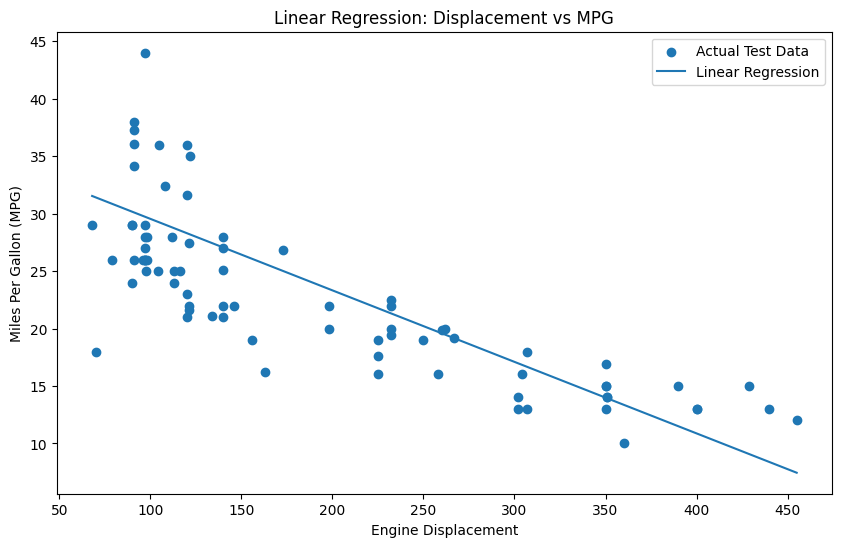

In [15]:

X_test_sorted = np.sort(X_test.values, axis=0)
y_linear_sorted = linear_model.predict(X_test_sorted)

plt.figure(figsize=(10, 6))

plt.scatter(
    X_test,
    y_test,
    label="Actual Test Data"
)

plt.plot(
    X_test_sorted,
    y_linear_sorted,
    label="Linear Regression"
)

plt.xlabel("Engine Displacement")
plt.ylabel("Miles Per Gallon (MPG)")
plt.title("Linear Regression: Displacement vs MPG")
plt.legend()
plt.show()

/home/netlab/.local/lib/python3.8/site-packages/sklearn/base.py:465: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/home/netlab/.local/lib/python3.8/site-packages/sklearn/base.py:465: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/home/netlab/.local/lib/python3.8/site-packages/sklearn/base.py:465: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/home/netlab/.local/lib/python3.8/site-packages/sklearn/base.py:465: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


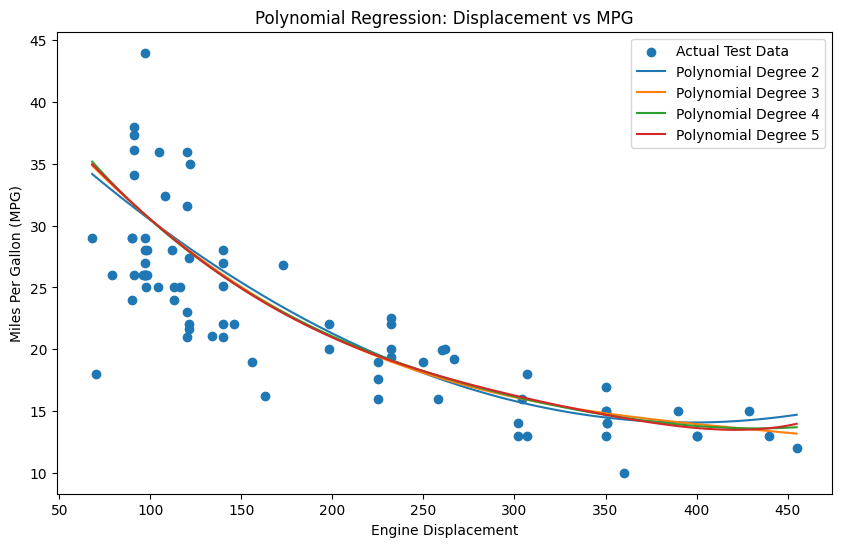

In [16]:

X_plot = np.linspace(
    X['displacement'].min(),
    X['displacement'].max(),
    300
).reshape(-1, 1)

plt.figure(figsize=(10, 6))


plt.scatter(
    X_test,
    y_test,
    label="Actual Test Data"
)


for degree in degrees:

    polynomial_model = make_pipeline(
        PolynomialFeatures(degree=degree),
        LinearRegression()
    )

    polynomial_model.fit(X_train, y_train)

    y_plot = polynomial_model.predict(X_plot)

    plt.plot(
        X_plot,
        y_plot,
        label=f"Polynomial Degree {degree}"
    )

plt.xlabel("Engine Displacement")
plt.ylabel("Miles Per Gallon (MPG)")
plt.title("Polynomial Regression: Displacement vs MPG")
plt.legend()
plt.show()

In [17]:
best_model = results_df.loc[
    results_df['R-squared'].idxmax()
]

print("Best Model:")
print(best_model)

Best Model:
Model        Polynomial Degree 2
MSE                    20.649055
R-squared               0.595439
Name: 1, dtype: object
